<a href="https://colab.research.google.com/github/kinjaljoshi/mech-interp-from-scratch/blob/master/superposition_revisit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Superposition.
A model wants to represent n features but has only m < n dimensions. Toy setup: sparse features x ∈ ℝⁿ, hidden h = Wx (W is m×n), output x̂ = ReLU(Wᵀh + b).

If features were stored orthogonally, you could keep only m of them. If features are sparse (rarely active together), the model can store more by giving them non-orthogonal directions. Overlap, called interference, rarely matters because two interfering features are rarely on at once, and the ReLU clips the negative leftovers.

Gram matrix G = WᵀW. The diagonal holds each feature’s squared length (is it represented?). The off-diagonals hold dot products between feature directions (how much two features interfere).

In [13]:
import torch, math

angles = torch.tensor([0, 2*math.pi/3, 4*math.pi/3])

print(torch.cos(angles))
print(torch.sin(angles))

W = torch.stack((torch.cos(angles), torch.sin(angles)))
print(W)

G = W.T @ W
print("G =", G)

expected = torch.full((3, 3), -0.5)
expected.fill_diagonal_(1.0)

print(expected)
print(torch.allclose(G, expected))

#one feature active and then 2
for x in [torch.tensor([1., 0., 0.]), torch.tensor([1., 1., 0.])]:
  h = W @ x
  print(x.tolist() , " => ", torch.relu(W.T @ h).round(decimals = 3).tolist())

tensor([ 1.0000, -0.5000, -0.5000])
tensor([ 0.0000,  0.8660, -0.8660])
tensor([[ 1.0000, -0.5000, -0.5000],
        [ 0.0000,  0.8660, -0.8660]])
G = tensor([[ 1.0000, -0.5000, -0.5000],
        [-0.5000,  1.0000, -0.5000],
        [-0.5000, -0.5000,  1.0000]])
tensor([[ 1.0000, -0.5000, -0.5000],
        [-0.5000,  1.0000, -0.5000],
        [-0.5000, -0.5000,  1.0000]])
True
[1.0, 0.0, 0.0]  =>  [1.0, 0.0, 0.0]
[1.0, 1.0, 0.0]  =>  [0.5, 0.5, 0.0]


1. **Feature 0 alone**: Wᵀh is [1, -0.5, -0.5]. The ReLU clips the two negatives to zero, so the output is perfectly clean.
2. **Features 0 and 1 together:** Wᵀh = Gx = [0.5, 0.5, -1]. Feature 2 would get an interference of -1, but it’s inactive and the ReLU clips it to zero, so that interference is free. Features 0 and 1 are different: their off-diagonal of -0.5 subtracts from each other, so each is reconstructed at 0.5 instead of 1.0.

Superposition costs model only when features are co-active. If co-activation is rare, which is exactly what sparsity means, the model pays little for packing in more features.

#Train the real toy model (5 features, 2 dimensions)

Training the toy model. Inputs are sparse: each feature is active with probability p, with a uniform(0,1) value when active. Loss is importance-weighted reconstruction error, Σᵢ Iᵢ (xᵢ − x̂ᵢ)², with importance decaying so feature 0 matters most. We train at two densities, dense (p = 1.0) and sparse (p = 0.05), and compare the diagonal of G = WᵀW, which is how much each feature is represented.

In [29]:
import torch, torch.nn as nn, math

torch.manual_seed(0)

n, m = 5, 2

importance = 0.9 ** torch.arange(n)
print(importance)

class toy_model(nn.Module):
  def __init__(self, n, m):
    super().__init__()
    self.W = nn.Parameter(torch.randn(m, n) * 0.5)
    self.bias = nn.Parameter(torch.zeros(n, ))
  def forward(self, X):
    h = X @ self.W.T
    return torch.relu(h @ self.W + self.bias)

def sample(batch, p):
  mask = torch.rand(batch, n) < p
  return torch.randn(batch, n) * mask.float()

def train(p, steps=5000):
  model = toy_model(n, m)
  opt = torch.optim.Adam(model.parameters(), lr=1e-2)
  for _ in range(steps):
    x= sample(1024, p)
    loss = (importance * (x - model(x)) ** 2).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
  return model, loss.item()

for p in [0.5, 0.1, 0.05]:
  model, loss = train(p)
  G = (model.W.T @ model.W).detach().round(decimals = 2)
  print(f"p = {p} | final loss = {loss:.4f}")
  print(f"Gram matrix -> \n {G.round(decimals=2)}")
  print("feature norms²:", G.diag().round(decimals=1).tolist())







tensor([1.0000, 0.9000, 0.8100, 0.7290, 0.6561])
p = 0.5 | final loss = 0.3166
Gram matrix -> 
 tensor([[ 1.0500,  0.0000,  0.0000,  0.0000, -0.1800],
        [ 0.0000,  1.0300, -0.2300, -0.1500, -0.0100],
        [ 0.0000, -0.2300,  0.0500,  0.0300,  0.0000],
        [ 0.0000, -0.1500,  0.0300,  0.0200,  0.0000],
        [-0.1800, -0.0100,  0.0000,  0.0000,  0.0300]])
feature norms²: [1.0, 1.0, 0.0, 0.0, 0.0]
p = 0.1 | final loss = 0.0640
Gram matrix -> 
 tensor([[ 1.1500, -0.4500,  0.0100,  0.4800,  0.1800],
        [-0.4500,  1.0600, -0.2700,  0.5100,  0.0200],
        [ 0.0100, -0.2700,  0.0800, -0.2000, -0.0200],
        [ 0.4800,  0.5100, -0.2000,  0.7400,  0.1500],
        [ 0.1800,  0.0200, -0.0200,  0.1500,  0.0400]])
feature norms²: [1.2000000476837158, 1.100000023841858, 0.10000000149011612, 0.699999988079071, 0.0]
p = 0.05 | final loss = 0.0380
Gram matrix -> 
 tensor([[ 1.1800, -0.5600,  0.5100, -0.2000, -0.0100],
        [-0.5600,  1.0600,  0.5300,  0.0200, -0.2300],
    

p=1.0   best loss=0.6261  represented=2  norms²=[1.0, 1.0, 0.0, 0.0, 0.0]
p=0.5   best loss=0.3108  represented=2  norms²=[1.0399999618530273, 1.0299999713897705, 0.05999999865889549, 0.009999999776482582, 0.009999999776482582]
p=0.2   best loss=0.1234  represented=3  norms²=[1.0700000524520874, 1.0099999904632568, 0.8399999737739563, 0.029999999329447746, 0.019999999552965164]
p=0.1   best loss=0.0603  represented=3  norms²=[1.1299999952316284, 1.0800000429153442, 0.8500000238418579, 0.05000000074505806, 0.07000000029802322]
p=0.05  best loss=0.0297  represented=3  norms²=[1.149999976158142, 1.0800000429153442, 0.9599999785423279, 0.07999999821186066, 0.03999999910593033]
p=0.02  best loss=0.0121  represented=3  norms²=[1.1699999570846558, 1.100000023841858, 1.0399999618530273, 0.03999999910593033, 0.029999999329447746]


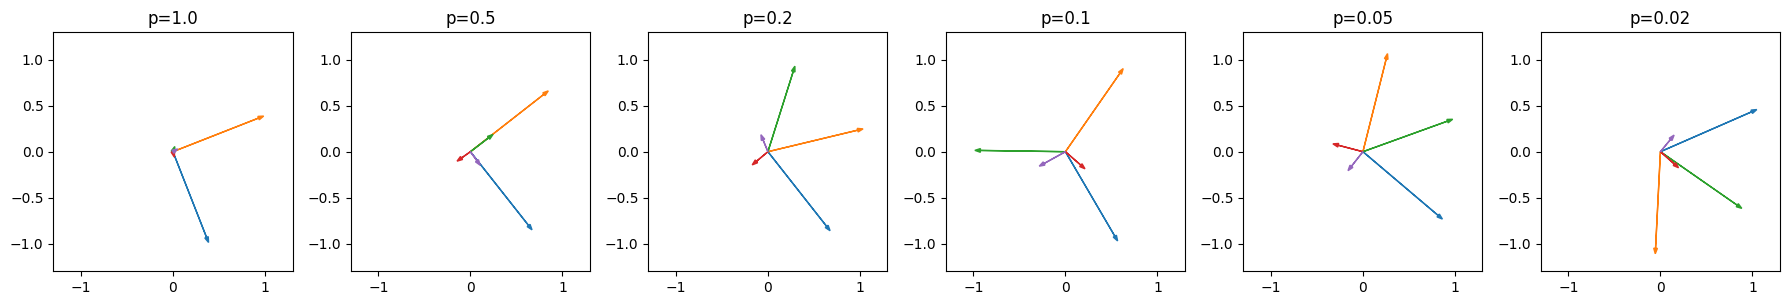

In [30]:
import matplotlib.pyplot as plt

def train2(p, seed, steps=8000):
    torch.manual_seed(seed)
    model = toy_model(n, m)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-2)
    for _ in range(steps):
        x = sample(1024, p)
        loss = (importance * (x - model(x)) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return model

def eval_loss(model, p):
    torch.manual_seed(999)
    with torch.no_grad():
        x = sample(20000, p)
        return (importance * (x - model(x)) ** 2).mean().item()

ps = [1.0, 0.5, 0.2, 0.1, 0.05, 0.02]
fig, axes = plt.subplots(1, len(ps), figsize=(3*len(ps), 3))
for ax, p in zip(axes, ps):
    runs = [train2(p, s) for s in range(5)]
    losses = [eval_loss(r, p) for r in runs]
    best = runs[losses.index(min(losses))]
    norms = (best.W.T @ best.W).diag().detach()
    print(f"p={p:<5} best loss={min(losses):.4f}  "
          f"represented={(norms > 0.5).sum().item()}  norms²={norms.round(decimals=2).tolist()}")
    W = best.W.detach()
    for i in range(n):
        ax.arrow(0, 0, W[0, i], W[1, i], head_width=0.04, color=f"C{i}")
    ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal")
    ax.set_title(f"p={p}")
plt.tight_layout(); plt.show()

#Dimensions per feature

Dimensions per feature. The Gram matrix tells us how much each feature interferes, but we want one number per feature. For feature i, with Ŵᵢ the unit vector along its direction, define

Dᵢ = ‖Wᵢ‖² / Σⱼ (Ŵᵢ · Wⱼ)²

The numerator is how strongly feature i is represented. The denominator is the total “noise” in its direction: its own contribution plus every other feature’s projection onto it. So Dᵢ is the fraction of a hidden dimension that feature i effectively gets.

A feature alone in its own dimension has D = 1.
A dropped feature has D = 0.
Features sharing space have 0 < D < 1.
Σᵢ Dᵢ is typically close to m, the number of hidden dimensions, because the model spends its whole budget.

In [31]:
importance = 0.9 ** torch.arange(n)

def dims_per_feature(W):
    # W: (m, n), columns are features
    norms2 = (W ** 2).sum(0)                              # ||W_i||^2
    What = W / (W.norm(dim=0, keepdim=True) + 1e-8)       # unit vectors
    denom = ((What.T @ W) ** 2).sum(1)                    # sum_j (What_i . W_j)^2
    return norms2 / (denom + 1e-8)

# 1) verify on the hand-built triangle
ang = torch.tensor([0, 2*math.pi/3, 4*math.pi/3])
W_tri = torch.stack([ang.cos(), ang.sin()])
print("triangle D:", dims_per_feature(W_tri).round(decimals=3).tolist(), "(expect 2/3 each)")

# 2) apply to the trained toy models across sparsity
for p in [1.0, 0.5, 0.2, 0.1, 0.05, 0.02]:
    runs = [train2(p, s) for s in range(5)]
    losses = [eval_loss(r, p) for r in runs]
    best = runs[losses.index(min(losses))]
    D = dims_per_feature(best.W.detach())
    print(f"p={p:<5} D={D.round(decimals=2).tolist()}  sum={D.sum().item():.2f}")

triangle D: [0.6669999957084656, 0.6669999957084656, 0.6669999957084656] (expect 2/3 each)
p=1.0   D=[1.0, 1.0, 0.0, 0.0, 0.0]  sum=2.00
p=0.5   D=[0.9900000095367432, 0.9300000071525574, 0.05999999865889549, 0.009999999776482582, 0.009999999776482582]  sum=2.00
p=0.2   D=[0.699999988079071, 0.699999988079071, 0.5699999928474426, 0.019999999552965164, 0.009999999776482582]  sum=2.00
p=0.1   D=[0.7099999785423279, 0.6700000166893005, 0.5400000214576721, 0.029999999329447746, 0.03999999910593033]  sum=2.00
p=0.05  D=[0.6899999976158142, 0.6600000262260437, 0.5799999833106995, 0.05000000074505806, 0.019999999552965164]  sum=2.00
p=0.02  D=[0.6899999976158142, 0.6600000262260437, 0.6100000143051147, 0.019999999552965164, 0.019999999552965164]  sum=2.00


#Reading the D values

1. Sum = 2.00 in every row. The model always spends its full budget of 2 hidden dimensions and splits it among the features it keeps. That’s the most robust result in the table.
2. p = 1.0 and 0.5: D ≈ [1, 1, 0, 0, 0]. Two features each get a whole dimension and the others get nothing, which is the orthogonal dense regime.
3. p = 0.2: D ≈ [0.70, 0.70, 0.57, 0, 0]. This is the transition. A third feature appears, so each of the three gets less than a full dimension. The change from p = 0.5 is abrupt, not gradual, which is a phase transition.
4. p = 0.1 down to 0.02: D ≈ [0.69, 0.66, 0.61]. All three sit near the triangle’s value of 2/3. At the sparse end the model has, in effect, found that triangle.
5. Features 3 and 4: D ≤ 0.06 at every p, so they’re essentially dropped.